In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
X, y_true = make_blobs(n_samples=500, centers=3, cluster_std=4, random_state=42)


In [3]:
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

In [4]:
df

,Feature_1,Feature_2
0,-2.282534,-9.692815
1,-6.147668,1.755990
2,13.399091,-1.260023
3,-4.077630,3.160226
4,9.444735,0.340868
...,...,...
495,-1.282205,-3.181575
496,-2.817604,10.378894
497,3.296740,8.649256
498,-8.970519,-2.684073


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [6]:
inertia = []
K_range = range(1, 11)

In [7]:
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

In [8]:
inertia

[999.9999999999994,
 528.8064432605648,
 294.4377068678187,
 250.4552469653444,
 216.88110656982604,
 185.274406751959,
 156.70879996290444,
 135.62603453115247,
 129.10396348239811,
 119.94101297104991]

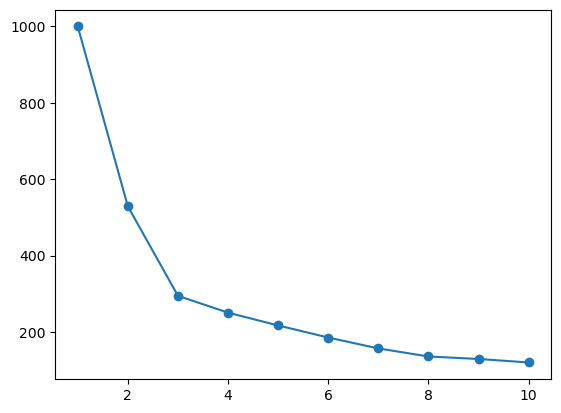

In [9]:
plt.plot(K_range, inertia, marker='o')

In [10]:
kmeans_final = KMeans(n_clusters=3, random_state=42)


In [11]:
cluster_labels = kmeans_final.fit_predict(X_scaled)


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [12]:
df['cluster'] = cluster_labels


<Axes: xlabel='Feature_1', ylabel='Feature_2'>

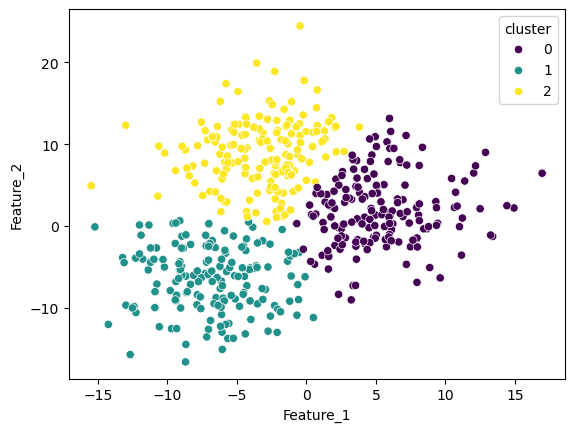

In [13]:
sns.scatterplot(x=df['Feature_1'],
                y=df['Feature_2'],
                hue=df['cluster'],
                palette='viridis')

In [14]:
from sklearn.datasets import make_moons


In [15]:
X, y_true = make_moons(n_samples=500, noise=0.05, random_state=42)


In [16]:
from sklearn.cluster import KMeans, DBSCAN

In [17]:
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])


In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [19]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [20]:
df['kmeans_cluster'] = kmeans_labels


<Axes: xlabel='Feature_1', ylabel='Feature_2'>

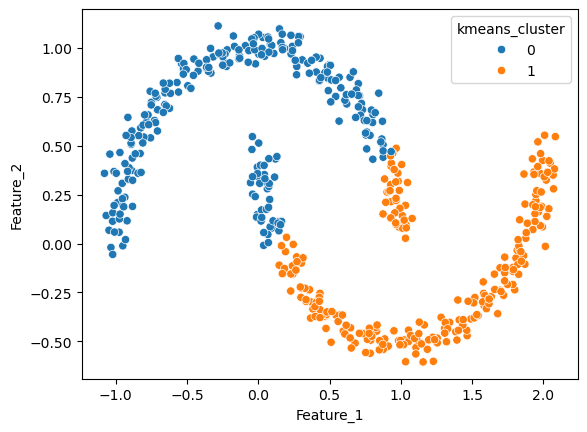

In [21]:
sns.scatterplot(x=df['Feature_1'], y=df['Feature_2'], hue=df['kmeans_cluster'], palette='tab10')


In [22]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [23]:
df['dbscan_cluster'] = dbscan_labels


<Axes: xlabel='Feature_1', ylabel='Feature_2'>

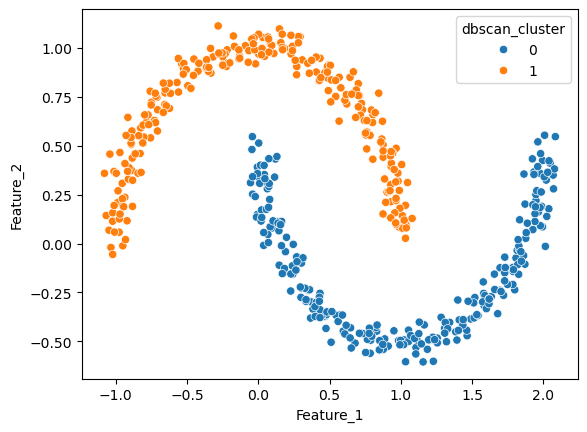

In [24]:
sns.scatterplot(x=df['Feature_1'], y=df['Feature_2'], hue=df['dbscan_cluster'], palette='tab10')


# ====================================================================================
## 🚀 ADVANCED CLUSTERING & ANOMALY DETECTION MASTERCLASS
### Topics Covered:
1. **DBSCAN in Depth**: Core points, border points, noise handling, non-convex geometry (`make_moons` & `make_circles`)
2. **KNN Clustering & Density Estimation**: K-Distance Graph (Elbow/Knee method) to find optimal $\epsilon$
3. **Hierarchical (Agglomerative) Clustering**: Linkage methods (Ward, Complete, Average, Single) & **Dendrograms**
4. **Random Forest Hierarchical Clustering**: Breiman's Unsupervised RF Proximity Matrix + Agglomerative Clustering
5. **Isolation Forest**: Tree-based Outlier & Anomaly Detection with 2D decision contours
6. **Top 20 Unsupervised Learning Interview Questions & Answers**
# ====================================================================================

### 1. DBSCAN vs K-Means on Complex Geometry
- **K-Means Limitation**: Assumes convex, spherical clusters of roughly equal variance. Fails completely on concentric circles or interleaving moons.
- **DBSCAN Advantage**: Groups points based on local density without assuming spherical shapes, and automatically isolates noise as cluster `-1`.

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


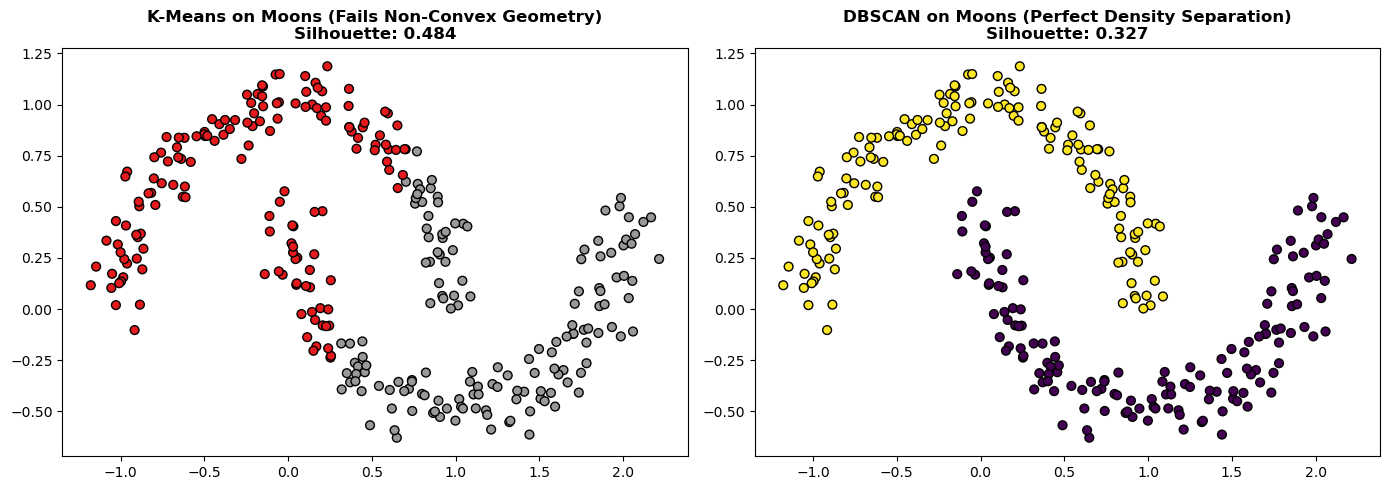

In [25]:
from sklearn.datasets import make_moons, make_circles
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score

X_moons, _ = make_moons(n_samples=300, noise=0.08, random_state=42)

# K-Means on moons
km_moons = KMeans(n_clusters=2, random_state=42).fit(X_moons)
# DBSCAN on moons
db_moons = DBSCAN(eps=0.2, min_samples=5).fit(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=km_moons.labels_, cmap='Set1', s=40, edgecolors='k')
axes[0].set_title(f'K-Means on Moons (Fails Non-Convex Geometry)\nSilhouette: {silhouette_score(X_moons, km_moons.labels_):.3f}', fontweight='bold')

axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=db_moons.labels_, cmap='viridis', s=40, edgecolors='k')
axes[1].set_title(f'DBSCAN on Moons (Perfect Density Separation)\nSilhouette: {silhouette_score(X_moons, db_moons.labels_):.3f}', fontweight='bold')
plt.tight_layout()
plt.show()

### 2. KNN Clustering & Density Estimation: Finding Optimal $\epsilon$ for DBSCAN via K-Distance Elbow
- Choosing $\epsilon$ arbitrarily leads to either 1 massive cluster (too large) or all points classified as noise (too small).
- **K-Distance Graph**: For every point, compute the distance to its $k^{\text{th}}$ nearest neighbor (`k = min_samples`). Sort the distances in ascending order and plot.
- The optimal $\epsilon$ is located at the **sharp elbow / knee** where distances abruptly escalate into noise!

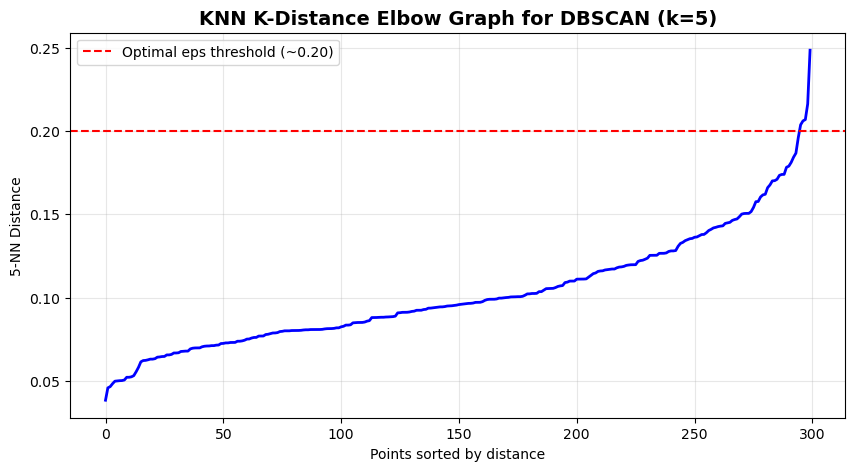

The sharp elbow around eps = 0.18 - 0.22 confirms the optimal neighborhood radius!


In [26]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

# 1. Compute distance to k-th nearest neighbor (k = min_samples = 5)
k = 5
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_moons)
distances, indices = nn.kneighbors(X_moons)

# Sort k-distances
k_distances = np.sort(distances[:, -1])

# 2. Plot K-distance elbow curve
plt.figure(figsize=(10, 5))
plt.plot(k_distances, color='blue', linewidth=2)
plt.axhline(y=0.20, color='red', linestyle='--', label='Optimal eps threshold (~0.20)')
plt.title(f'KNN K-Distance Elbow Graph for DBSCAN (k={k})', fontsize=14, fontweight='bold')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'{k}-NN Distance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("The sharp elbow around eps = 0.18 - 0.22 confirms the optimal neighborhood radius!")

### 3. Hierarchical (Agglomerative) Clustering & Dendrograms
- **Agglomerative (Bottom-Up)**: Every observation starts as its own cluster. At each iteration, the two most similar clusters merge until one tree remains.
- **Linkage Criteria**:
  1. **Ward**: Minimizes within-cluster variance $\Delta \text{Var}$ (most common, forms spherical compact clusters).
  2. **Complete**: Maximum distance between points in clusters: $d(A, B) = \max_{a \in A, b \in B} d(a, b)$.
  3. **Average**: Mean pairwise distance: $d(A, B) = \frac{1}{|A||B|} \sum d(a, b)$.
  4. **Single**: Minimum pairwise distance: $d(A, B) = \min_{a \in A, b \in B} d(a, b)$ (detects non-elliptical shapes, prone to chaining).

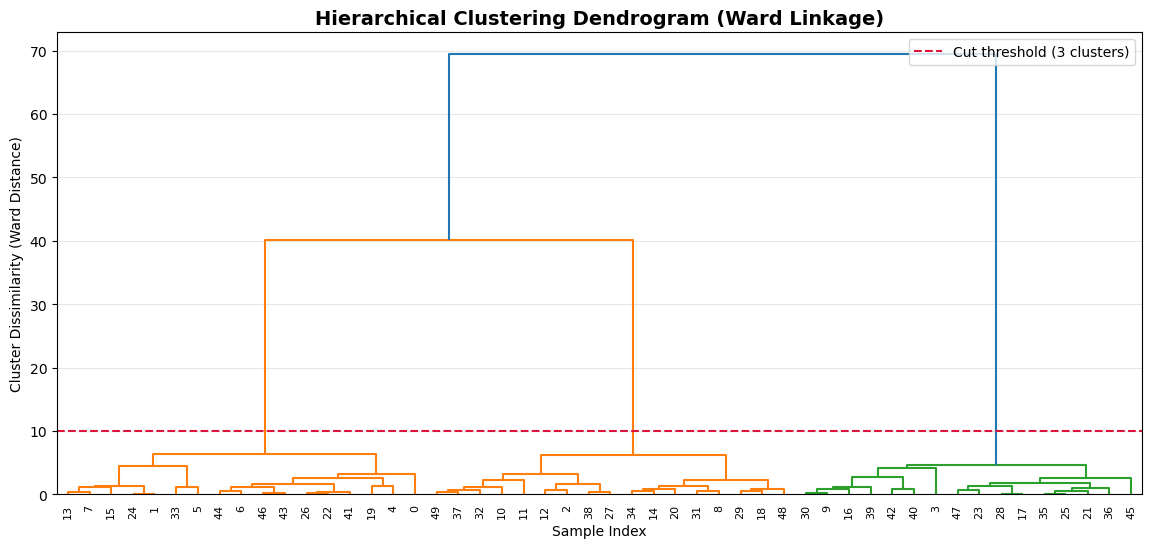

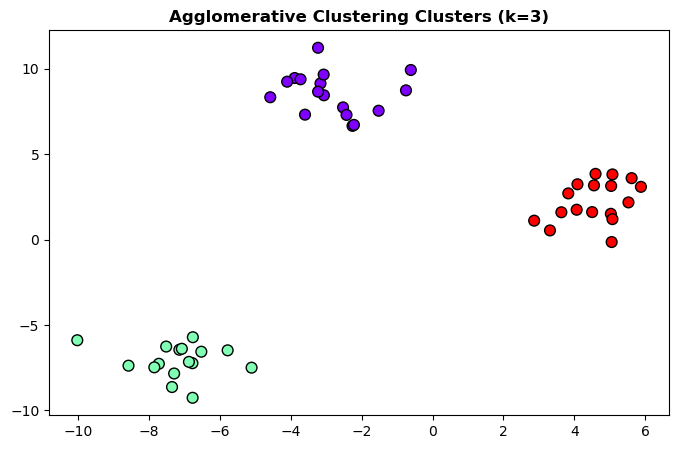

In [27]:
import seaborn as sns
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Generate sample blob data for hierarchical clustering demonstration
X_hier, _ = make_blobs(n_samples=50, centers=3, cluster_std=1.2, random_state=42)

# Compute linkage matrix using Ward method
linked = linkage(X_hier, method='ward')

# Plot Dendrogram
plt.figure(figsize=(14, 6))
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True)
plt.axhline(y=10, color='crimson', linestyle='--', label='Cut threshold (3 clusters)')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=14, fontweight='bold')
plt.xlabel('Sample Index')
plt.ylabel('Cluster Dissimilarity (Ward Distance)')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

# Fit Agglomerative Clustering
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg.fit_predict(X_hier)

plt.figure(figsize=(8, 5))
plt.scatter(X_hier[:, 0], X_hier[:, 1], c=agg_labels, cmap='rainbow', s=60, edgecolors='k')
plt.title('Agglomerative Clustering Clusters (k=3)', fontweight='bold')
plt.show()

### 4. Random Forest Hierarchical Clustering (Unsupervised RF Proximity Matrix)
#### How does Random Forest perform Unsupervised Clustering?
Leo Breiman introduced **Random Forest Proximity-Based Clustering**:
1. Train an ensemble of random trees.
2. For every pair of samples $(x_i, x_j)$, calculate how often they land in the **same terminal leaf** across all $B$ trees: $\text{Proximity}(i, j) = \frac{1}{B} \sum_{b=1}^B \mathbb{I}(\text{leaf}_b(x_i) == \text{leaf}_b(x_j))$.
3. If two samples are similar across feature subspace combinations, their proximity approaches $1.0$.
4. Define distance $D(i, j) = 1 - \text{Proximity}(i, j)$.
5. Feed this precomputed distance matrix into **Agglomerative Hierarchical Clustering**!

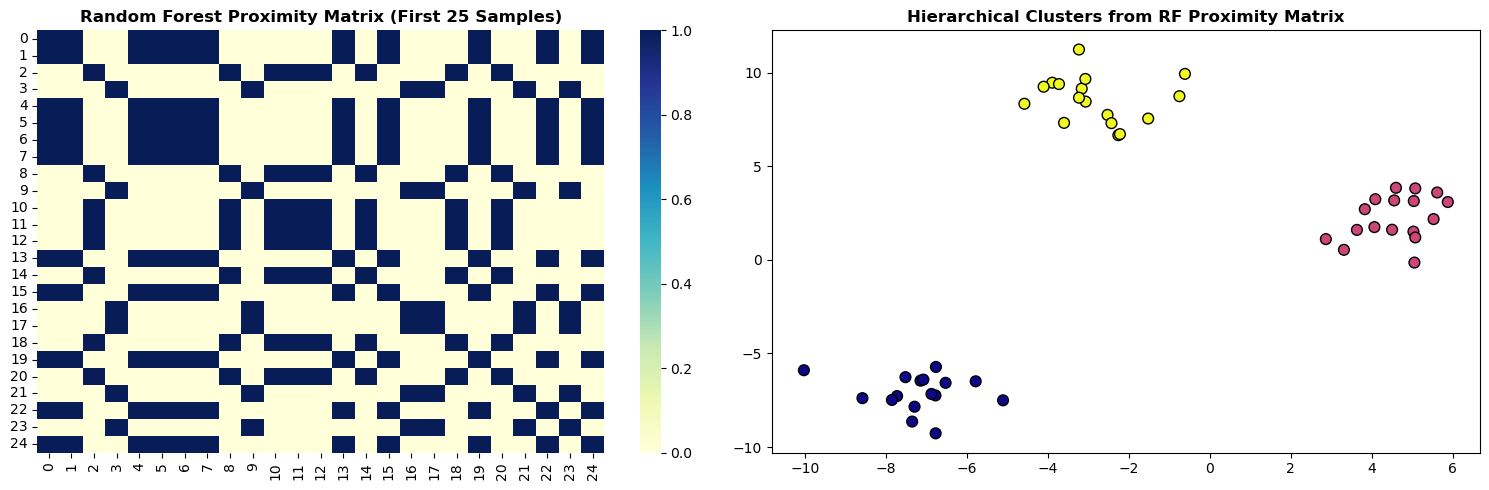

Random Forest Proximity-Based Hierarchical Clustering successfully executed!


In [28]:
from sklearn.ensemble import RandomForestClassifier

# Step 1: Fit Random Forest
rf_cluster = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
# We fit on the data (using cluster pseudo-labels or unsupervised mode)
rf_cluster.fit(X_hier, agg_labels)

# Step 2: Extract leaf indices for all samples across all 100 trees (shape: [n_samples, n_estimators])
leaf_assignments = rf_cluster.apply(X_hier)

# Step 3: Compute Proximity Matrix
n_samples = len(X_hier)
rf_proximity = np.zeros((n_samples, n_samples))
for t in range(rf_cluster.n_estimators):
    leaves_t = leaf_assignments[:, t]
    rf_proximity += (leaves_t[:, None] == leaves_t[None, :]).astype(float)
rf_proximity /= rf_cluster.n_estimators

# Step 4: Convert Proximity to Distance Matrix
rf_distance_matrix = 1.0 - rf_proximity

# Step 5: Hierarchical Clustering on RF Proximity Distance Matrix
rf_hier = AgglomerativeClustering(n_clusters=3, metric='precomputed', linkage='average')
rf_hier_labels = rf_hier.fit_predict(rf_distance_matrix)

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(rf_proximity[:25, :25], cmap='YlGnBu', ax=axes[0])
axes[0].set_title('Random Forest Proximity Matrix (First 25 Samples)', fontweight='bold')

axes[1].scatter(X_hier[:, 0], X_hier[:, 1], c=rf_hier_labels, cmap='plasma', s=60, edgecolors='k')
axes[1].set_title('Hierarchical Clusters from RF Proximity Matrix', fontweight='bold')
plt.tight_layout()
plt.show()
print("Random Forest Proximity-Based Hierarchical Clustering successfully executed!")

### 5. Isolation Forest: Tree-Based Outlier & Anomaly Detection
- **Intuition**: Outliers are few and attribute-different. When randomly partitioning feature space with random cuts, anomalies are **isolated quickly** near the root of the tree.
- **Path Length $h(x)$**: Shorter average path length across ensemble of $iTrees$ $\implies$ high likelihood of being an anomaly!
- **Contamination**: Expected proportion of anomalies in the dataset.

C:\Users\ayush\AppData\Local\Temp\ipykernel_22440\240963791.py:25: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_iso[iso_preds == -1, 0], X_iso[iso_preds == -1, 1], c='red', edgecolors='black', s=70, marker='x', label='Detected Outliers (Prediction = -1)')


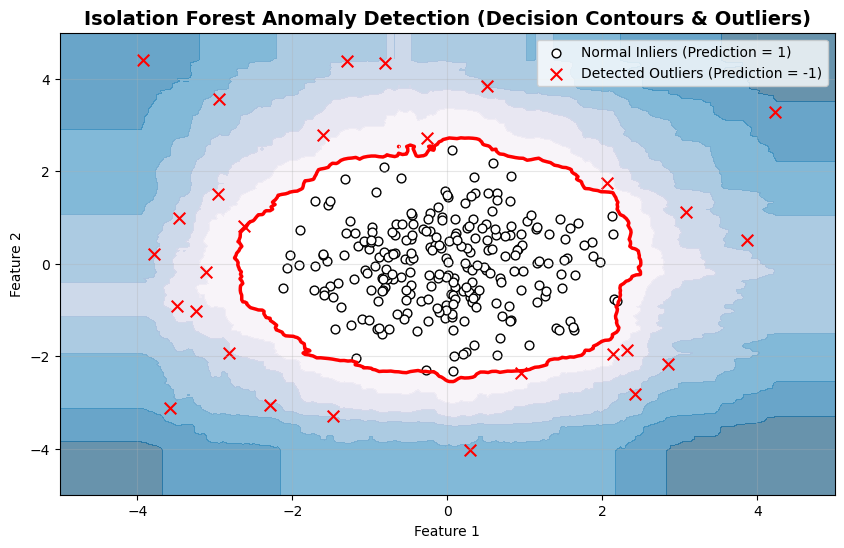

Total samples: 275 | Outliers detected: 28


In [29]:
from sklearn.ensemble import IsolationForest

# Generate inliers and synthetic outliers
np.random.seed(42)
inliers = np.random.normal(loc=0, scale=1.0, size=(250, 2))
outliers = np.random.uniform(low=-4.5, high=4.5, size=(25, 2))
X_iso = np.vstack([inliers, outliers])

# Fit Isolation Forest
iso_forest = IsolationForest(n_estimators=100, contamination=0.10, random_state=42)
iso_forest.fit(X_iso)

# Predict labels (1 = inlier, -1 = outlier) and anomaly scores
iso_preds = iso_forest.predict(X_iso)
anomaly_scores = iso_forest.decision_function(X_iso)

# Visualize Isolation Forest Anomaly Boundary
xx, yy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
Z_iso = iso_forest.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z_iso, levels=np.linspace(Z_iso.min(), 0, 8), cmap=plt.cm.PuBu_r, alpha=0.6)
plt.contour(xx, yy, Z_iso, levels=[0], linewidths=2.5, colors='red')
plt.scatter(X_iso[iso_preds == 1, 0], X_iso[iso_preds == 1, 1], c='white', edgecolors='black', s=40, label='Normal Inliers (Prediction = 1)')
plt.scatter(X_iso[iso_preds == -1, 0], X_iso[iso_preds == -1, 1], c='red', edgecolors='black', s=70, marker='x', label='Detected Outliers (Prediction = -1)')
plt.title('Isolation Forest Anomaly Detection (Decision Contours & Outliers)', fontsize=14, fontweight='bold')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Total samples: {len(X_iso)} | Outliers detected: {np.sum(iso_preds == -1)}")

### 6. Top 20 Unsupervised Learning Interview Questions & Answers

| # | Question | Comprehensive Interview-Grade Answer |
|---|---|---|
| **1** | **How does DBSCAN determine Core, Border, and Noise points?** | (1) **Core Point**: Has $\ge \text{MinPts}$ points within its $\epsilon$-radius $N_\epsilon(p)$. (2) **Border Point**: Within $\epsilon$-radius of a core point but has $< \text{MinPts}$ neighbors itself. (3) **Noise Point**: Neither core nor border; assigned label $-1$. |
| **2** | **How do you find the optimal $\epsilon$ for DBSCAN?** | Compute the $k$-nearest neighbor distance for each point (with $k = \text{MinPts}$). Sort distances in ascending order and plot the **K-Distance Graph**. The optimal $\epsilon$ corresponds to the **elbow/knee** where distances sharply transition from cluster density to sparse noise. |
| **3** | **Why does K-Means fail on non-spherical clusters while DBSCAN succeeds?** | K-Means minimizes inertia $\sum \|x - \mu_k\|^2$, implicitly assuming isotropic spherical Gaussian clusters of equal variance with linear decision boundaries (Voronoi cells). DBSCAN uses connected density components, allowing it to trace arbitrary manifolds (e.g. concentric circles, moons). |
| **4** | **What is the difference between Ward, Complete, Average, and Single Linkage in Hierarchical Clustering?** | **Ward**: Merges clusters minimizing increase in total within-cluster variance. **Complete**: Merges clusters with smallest maximum pairwise distance (compact clusters). **Average**: Merges clusters with smallest average pairwise distance. **Single**: Merges clusters with smallest minimum pairwise distance (prone to *chaining effect*). |
| **5** | **How does Random Forest perform Unsupervised Clustering?** | It builds an $N \times N$ **proximity matrix**: for every tree in the forest, if sample $i$ and $j$ land in the exact same terminal leaf, their proximity score increases by $1/B$. Converting this to distance $D = 1 - \text{Proximity}$ allows applying Hierarchical Clustering to capture complex non-linear feature interactions without manual distance formulas. |
| **6** | **How does Isolation Forest detect outliers?** | It isolates anomalies instead of profiling normal points. Since anomalies are sparse and distant, they require significantly fewer random splits to isolate, resulting in a **short path length** $h(x)$ from tree root to leaf. Anomaly score $s(x, n) = 2^{-E(h(x))/c(n)}$. |
| **7** | **What is the time complexity of Isolation Forest vs Local Outlier Factor (LOF)?** | Isolation Forest is $O(t \cdot n \log \psi)$ (linear, where $t$ is trees and $\psi$ is subsample size), making it scalable to millions of rows. LOF relies on nearest neighbor distance search $O(n^2)$, making it computationally prohibitive for large datasets. |
| **8** | **What is the Silhouette Score and what do its values mean?** | $s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$, where $a(i)$ is mean intra-cluster distance and $b(i)$ is mean nearest-cluster distance. Range: $[-1, 1]$. $+1$: perfectly matched to own cluster and far from neighbors. $0$: on border between clusters. $-1$: point misassigned to wrong cluster. |
| **9** | **What is Davies-Bouldin Index and Calinski-Harabasz Index?** | **Davies-Bouldin Index (DBI)**: Ratio of within-cluster scatter to separation between clusters; **lower is better**. **Calinski-Harabasz Index (CHI)**: Ratio of between-cluster dispersion to within-cluster dispersion (Variance Ratio Criterion); **higher is better**. |
| **10** | **Why is feature scaling essential before K-Means, DBSCAN, and Hierarchical Clustering?** | All three compute Euclidean distances. If feature $A$ has scale $[0, 100000]$ and feature $B$ has scale $[0, 1]$, distances are entirely dominated by feature $A$. Without scaling, the clustering algorithm essentially ignores all other dimensions. |
| **11** | **Can DBSCAN cluster in high dimensions?** | It struggles due to the **Curse of Dimensionality**: in high dimensions, points become equidistant ($d_{\max} \approx d_{\min}$), making density estimation unstable and choosing a single $\epsilon$ across the space difficult. Solution: Apply PCA, t-SNE, or HDBSCAN. |
| **12** | **What is HDBSCAN and how does it improve over DBSCAN?** | Hierarchical DBSCAN performs DBSCAN over varying $\epsilon$ values and extracts clusters based on cluster stability (persistence across density thresholds). It handles clusters of **varying densities**, overcoming DBSCAN's major limitation of a single global $\epsilon$. |
| **13** | **What is the Elbow Method and why can it be ambiguous?** | Plots inertia (sum of squared distances to centroids) vs $K$. As $K$ increases, inertia monotonically decreases. The elbow point marks diminishing returns. It can be ambiguous when the curve bends smoothly without a sharp kink. Use Silhouette Analysis to resolve ambiguity. |
| **14** | **What is K-Means++ and why is it superior to random initialization?** | Standard K-Means randomly picks initial centroids, risking poor local minima. K-Means++ picks the 1st centroid randomly, then chooses subsequent centroids with probability proportional to their squared distance from existing centroids $D(x)^2$, ensuring widely dispersed initial centroids and faster $O(\log K)$ convergence. |
| **15** | **How does K-Medoids (PAM) differ from K-Means?** | K-Means uses cluster means (centroids), which are sensitive to outliers and require Euclidean distance. K-Medoids chooses actual data points as centers (medoids) and minimizes sum of dissimilarities (e.g. Manhattan distance), making it robust to extreme outliers. |
| **16** | **What is the Chaining Effect in Hierarchical Single Linkage?** | Because single linkage defines distance as $\min d(a, b)$, a single straggling line of noise points can bridge two separate dense clusters together, merging them into one long chain. |
| **17** | **Can Hierarchical Clustering handle streaming or massive datasets?** | No. Agglomerative clustering requires storing the $O(n^2)$ pairwise distance matrix and takes $O(n^3)$ or $O(n^2 \log n)$ time, making it impractical for $n > 20,000$. |
| **18** | **How does Gaussian Mixture Models (GMM) generalize K-Means?** | GMM is a probabilistic soft-clustering method using the Expectation-Maximization (EM) algorithm. Each cluster is modeled by a Gaussian distribution with its own mean $\mu_k$ and covariance matrix $\Sigma_k$. Points receive soft membership probabilities $P(C_k|x)$ instead of hard binary assignments. |
| **19** | **What is the difference between Transductive and Inductive Clustering?** | **Transductive** (e.g. standard Agglomerative / Spectral clustering): only groups the provided dataset; cannot predict cluster labels for new incoming points without re-clustering. **Inductive** (e.g. K-Means, GMM, Trained Random Forest): learns centroids or decision rules and can immediately assign cluster labels to unseen test points via `predict()`. |
| **20** | **When should you choose Isolation Forest over One-Class SVM?** | Use **Isolation Forest** for tabular datasets with medium to high dimensions; it is faster ($O(n \log n)$), requires minimal tuning, and is robust against hyperparameter sensitivity. Use **One-Class SVM** when boundary geometry is strictly known or working with kernelized spaces, though it is computationally heavier ($O(n^2)$). |